In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

## Описание данных

Демографические и социально-экономические признаки:

person_id – Уникальный идентификатор для каждого человека

age – Возраст индивидуума (18–90 лет)

sex – Пол (мужской/женский)

region – Географический регион

urban_rural – Проживает ли человек в городской или сельской местности

income – Годовой доход (долл. США)

education – Уровень образования

marital_status – Семейное положение

employment_status – Тип/статус занятости

household_size – Количество человек в домохозяйстве

dependents – Количество финансово иждивенцев

Образ жизни и привычки:

bmi – Значение индекса массы тела

smoker – Статус курения (Да/Нет)

alcohol_freq – Частота употребления алкоголя

Здоровье и показатели здоровья:

chronic_count – Количество диагностированных хронических заболеваний

hypertension – Показатель диагностированной гипертонии (0 = Нет, 1 = Да)

diabetes – Показатель диагностики диабета (0 = Нет, 1 = Да)

asthma – Показатель диагностики астмы (0 = Нет, 1 = Да)

copd – Показатель хронической обструктивной болезни легких (0 = нет, 1 = да)

cardiovascular – Наличие сердечно-сосудистых заболеваний (0 = Нет, 1 = Да)

cancer_history – История диагноза рака (0 = Нет, 1 = Да)

kidney_disease – Показатель хронической болезни почек (0 = Нет, 1 = Да)

liver_disease – Индикатор заболевания печени (0 = Нет, 1 = Да)

arthritis – Показатель для диагностики артрита (0 = Нет, 1 = Да)

mental_health – Наличие диагностированного психического расстройства (0 = Нет, 1 = Да)

systolic_bp – Систолическое артериальное давление (мм рт. ст.)

diastolic_bp – Диастолическое артериальное давление (мм рт. ст.)

ldl – Уровень холестерина ЛПНП (мг/дл)

hba1c – Процент гемоглобина A1c (показатель контроля уровня сахара в крови)

risk_score – Расчетный показатель риска для здоровья (нормализованный)

is_high_risk – Двоичный индикатор, если человек классифицируется как имеющий высокий риск для здоровья (0 = Нет, 1 = Да)

Использование медицинской помощи и процедуры:

visits_last_year – Количество посещений медицинских учреждений за последний год

hospitalizations_last_3yrs – Количество госпитализаций за последние три года

days_hospitalized_last_3yrs – Общее количество дней, проведенных в больнице за последние три года

medication_count – Количество назначенных активных лекарств

proc_imaging_count – Количество процедур с визуализацией (например, рентгенография, МРТ, КТ), выполненных в год

proc_surgery_count – Количество перенесенных хирургических операций

proc_physio_count – Количество психиатрических/психологических процедур или сеансов

proc_consult_count – Количество консультаций специалистов (например, кардиолога, онколога)

proc_lab_count – Количество проведенных лабораторных диагностических исследований

had_major_procedure – Индикатор, было ли у человека серьезное медицинское событие (например, операция, госпитализация)

Страхование и полис:

plan_type – Тип страхового плана (например, HMO, PPO, EPO)

network_tier – Сетевой уровень страковки (базовый, серебряный, золотой, платиновый)

deductible – Годовая сумма вычета в долларах США

copay – Сумма доплаты за услугу здравоохранения

policy_term_years – Срок действия страхового полиса в годах

policy_changes_last_2yrs – Количество изменений политики полиса за последние два года изменения полиса за последние 2 года

provider_quality – Рейтинг качества поставщика первичной медицинской помощи/страховщика

Медицинские расходы и страховые требования:

annual_medical_cost – Общие годовые медицинские расходы в долларах США (целевой признак)

annual_premium – Годовая страховая премия в долларах США

monthly_premium – Ежемесячная страховая премия в долларах США

claims_count – Количество страховых исков, поданных за год

avg_claim_amount – Средняя сумма иска в долларах США

total_claims_paid – Общая сумма претензий, выплаченных в долларах США

## Первичная обработка и исследование признаков

In [2]:
df = pd.read_csv('medical_insurance.csv')

In [3]:
df.isnull().sum()

person_id                          0
age                                0
sex                                0
region                             0
urban_rural                        0
income                             0
education                          0
marital_status                     0
employment_status                  0
household_size                     0
dependents                         0
bmi                                0
smoker                             0
alcohol_freq                   30083
visits_last_year                   0
hospitalizations_last_3yrs         0
days_hospitalized_last_3yrs        0
medication_count                   0
systolic_bp                        0
diastolic_bp                       0
ldl                                0
hba1c                              0
plan_type                          0
network_tier                       0
deductible                         0
copay                              0
policy_term_years                  0
p

In [4]:
df['alcohol_freq'] = df['alcohol_freq'].fillna('Not answered')

In [5]:
df['alcohol_freq'].value_counts()

alcohol_freq
Occasional      45078
Not answered    30083
Weekly          19833
Daily            5006
Name: count, dtype: int64

In [6]:
df.drop('person_id',axis=1, inplace=True)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 53 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   age                          100000 non-null  int64  
 1   sex                          100000 non-null  str    
 2   region                       100000 non-null  str    
 3   urban_rural                  100000 non-null  str    
 4   income                       100000 non-null  float64
 5   education                    100000 non-null  str    
 6   marital_status               100000 non-null  str    
 7   employment_status            100000 non-null  str    
 8   household_size               100000 non-null  int64  
 9   dependents                   100000 non-null  int64  
 10  bmi                          100000 non-null  float64
 11  smoker                       100000 non-null  str    
 12  alcohol_freq                 100000 non-null  str    
 13  visits_last

In [8]:
columns_already_unpacked = [col for col in df.columns if len(df[col].unique()) == 2]
columns_already_unpacked

['hypertension',
 'diabetes',
 'asthma',
 'copd',
 'cardiovascular_disease',
 'cancer_history',
 'kidney_disease',
 'liver_disease',
 'arthritis',
 'mental_health',
 'is_high_risk',
 'had_major_procedure']

In [9]:
df

,age,sex,region,urban_rural,income,education,marital_status,employment_status,household_size,dependents,...,liver_disease,arthritis,mental_health,proc_imaging_count,proc_surgery_count,proc_physio_count,proc_consult_count,proc_lab_count,is_high_risk,had_major_procedure
0,52,Female,North,Suburban,22700.0,Doctorate,Married,Retired,3,1,...,0,1,0,1,0,2,0,1,0,0
1,79,Female,North,Urban,12800.0,No HS,Married,Employed,3,1,...,0,1,1,0,0,1,0,1,1,0
2,68,Male,North,Rural,40700.0,HS,Married,Retired,5,3,...,0,0,1,1,0,2,1,0,1,0
3,15,Male,North,Suburban,15600.0,Some College,Married,Self-employed,5,3,...,0,0,0,1,0,0,1,0,0,0
4,53,Male,Central,Suburban,89600.0,Doctorate,Married,Self-employed,2,0,...,0,1,0,2,0,1,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,50,Male,West,Urban,127200.0,No HS,Married,Employed,2,0,...,0,0,0,0,0,1,0,0,0,0
99996,42,Male,East,Suburban,21600.0,HS,Married,Employed,2,0,...,0,0,0,0,0,0,0,0,0,0
99997,41,Male,West,Rural,81900.0,HS,Divorced,Unemployed,1,0,...,0,0,0,1,0,1,0,0,0,0
99998,51,Female,South,Urban,43400.0,Doctorate,Single,Unemployed,3,2,...,0,0,1,0,0,2,2,1,0,0


In [10]:
df.drop(columns_already_unpacked + list(df.select_dtypes('str').columns), axis=1).describe().drop('count')

,age,income,household_size,dependents,bmi,visits_last_year,hospitalizations_last_3yrs,days_hospitalized_last_3yrs,medication_count,systolic_bp,...,monthly_premium,claims_count,avg_claim_amount,total_claims_paid,chronic_count,proc_imaging_count,proc_surgery_count,proc_physio_count,proc_consult_count,proc_lab_count
mean,47.521500,4.987390e+04,2.430900,0.898380,26.990512,1.92765,0.093640,0.373350,1.236320,117.808970,...,48.526668,1.62178,656.512084,1377.878827,0.724720,0.508530,0.158690,0.508390,0.50933,0.509140
std,15.988752,4.680021e+04,1.075126,0.950654,4.994883,1.73773,0.304848,1.373011,1.209358,15.369187,...,33.298640,2.02982,1072.660048,2305.464687,0.805523,0.749755,0.463562,0.747218,0.75363,0.750455
min,0.000000,1.100000e+03,1.000000,0.000000,12.000000,0.00000,0.000000,0.000000,0.000000,61.000000,...,17.640000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000
25%,37.000000,2.110000e+04,2.000000,0.000000,23.600000,1.00000,0.000000,0.000000,0.000000,107.000000,...,29.340000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000
50%,48.000000,3.620000e+04,2.000000,1.000000,27.000000,2.00000,0.000000,0.000000,1.000000,117.000000,...,38.630000,1.00000,318.015000,642.545000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000
75%,58.000000,6.220000e+04,3.000000,1.000000,30.400000,3.00000,0.000000,0.000000,2.000000,128.000000,...,55.560000,2.00000,872.215000,1795.522500,1.000000,1.000000,0.000000,1.000000,1.00000,1.000000
max,100.000000,1.061800e+06,9.000000,7.000000,50.400000,25.00000,3.000000,21.000000,11.000000,183.000000,...,913.550000,23.00000,30010.530000,72517.950000,6.000000,7.000000,6.000000,7.000000,7.00000,7.000000


In [11]:
len(df.drop(columns_already_unpacked + list(df.select_dtypes('str').columns), axis=1).columns)

31

In [12]:
plt.figure(figsize=(18,14), dpi=1000)
for i,col in enumerate(df.drop(columns_already_unpacked + list(df.select_dtypes('str').columns), axis=1).columns):
    plt.subplot(7, 5, i+1)
    sns.boxplot(df[col])
plt.tight_layout()

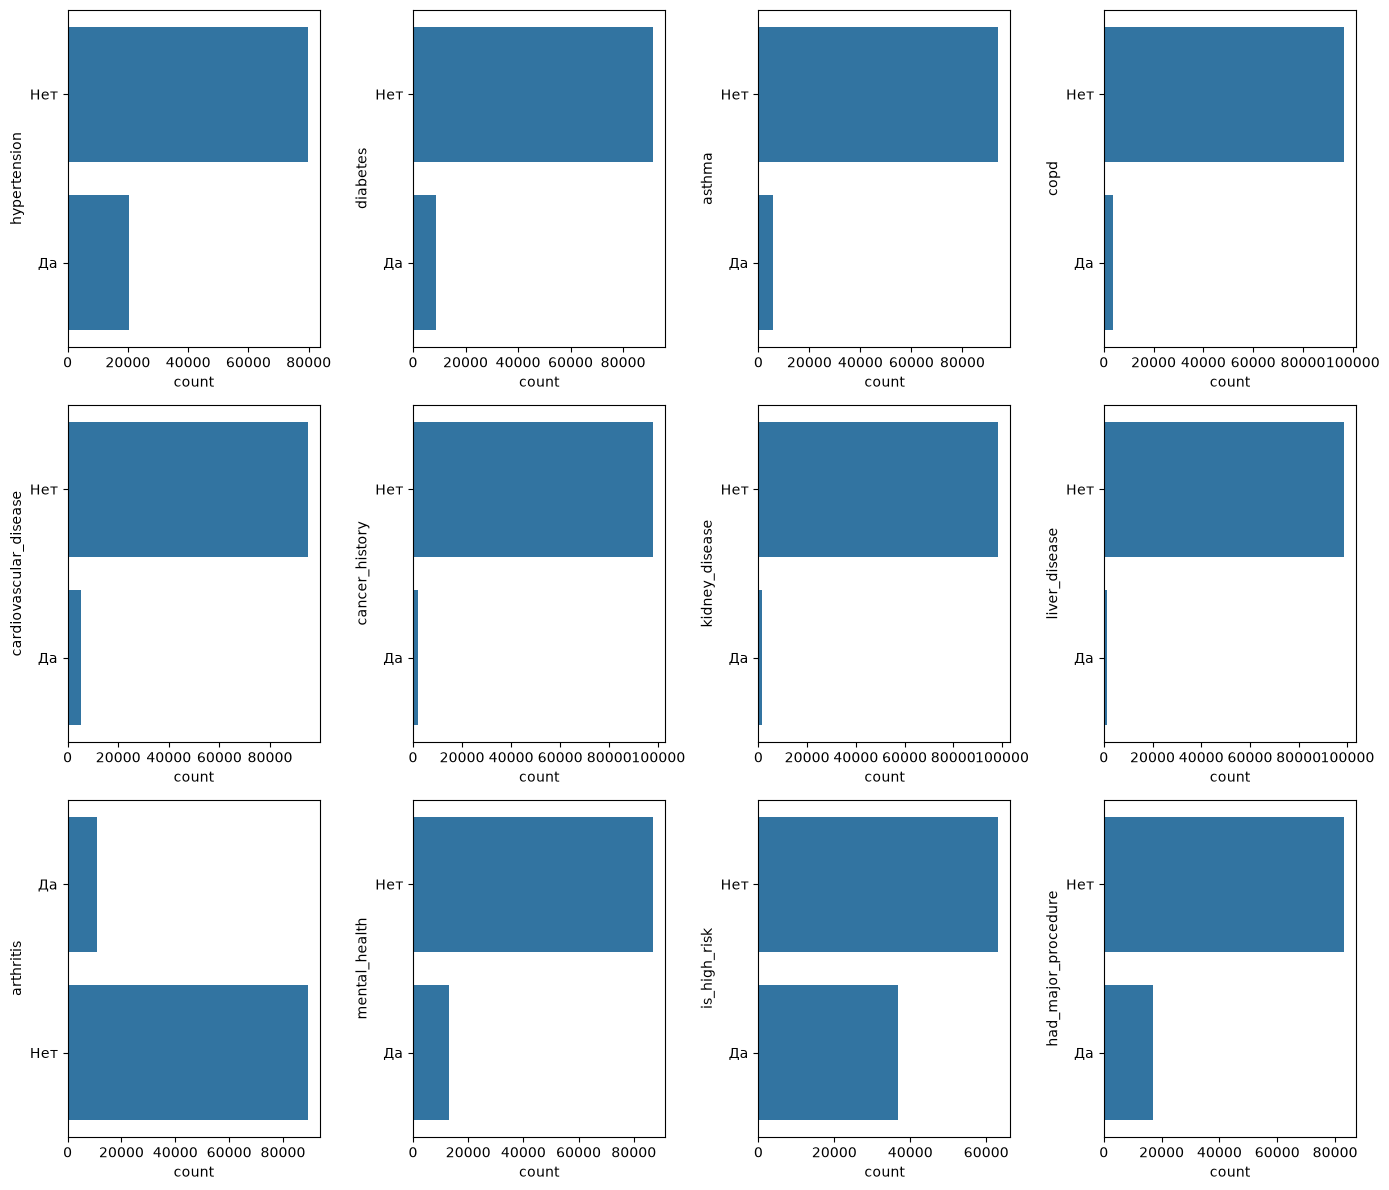

In [13]:
plt.figure(figsize=(14,12))
for i,col in enumerate(columns_already_unpacked):
    plt.subplot(3, 4, i+1)
    sns.countplot(df[col].map({1: 'Да', 0:'Нет'}))
plt.tight_layout()

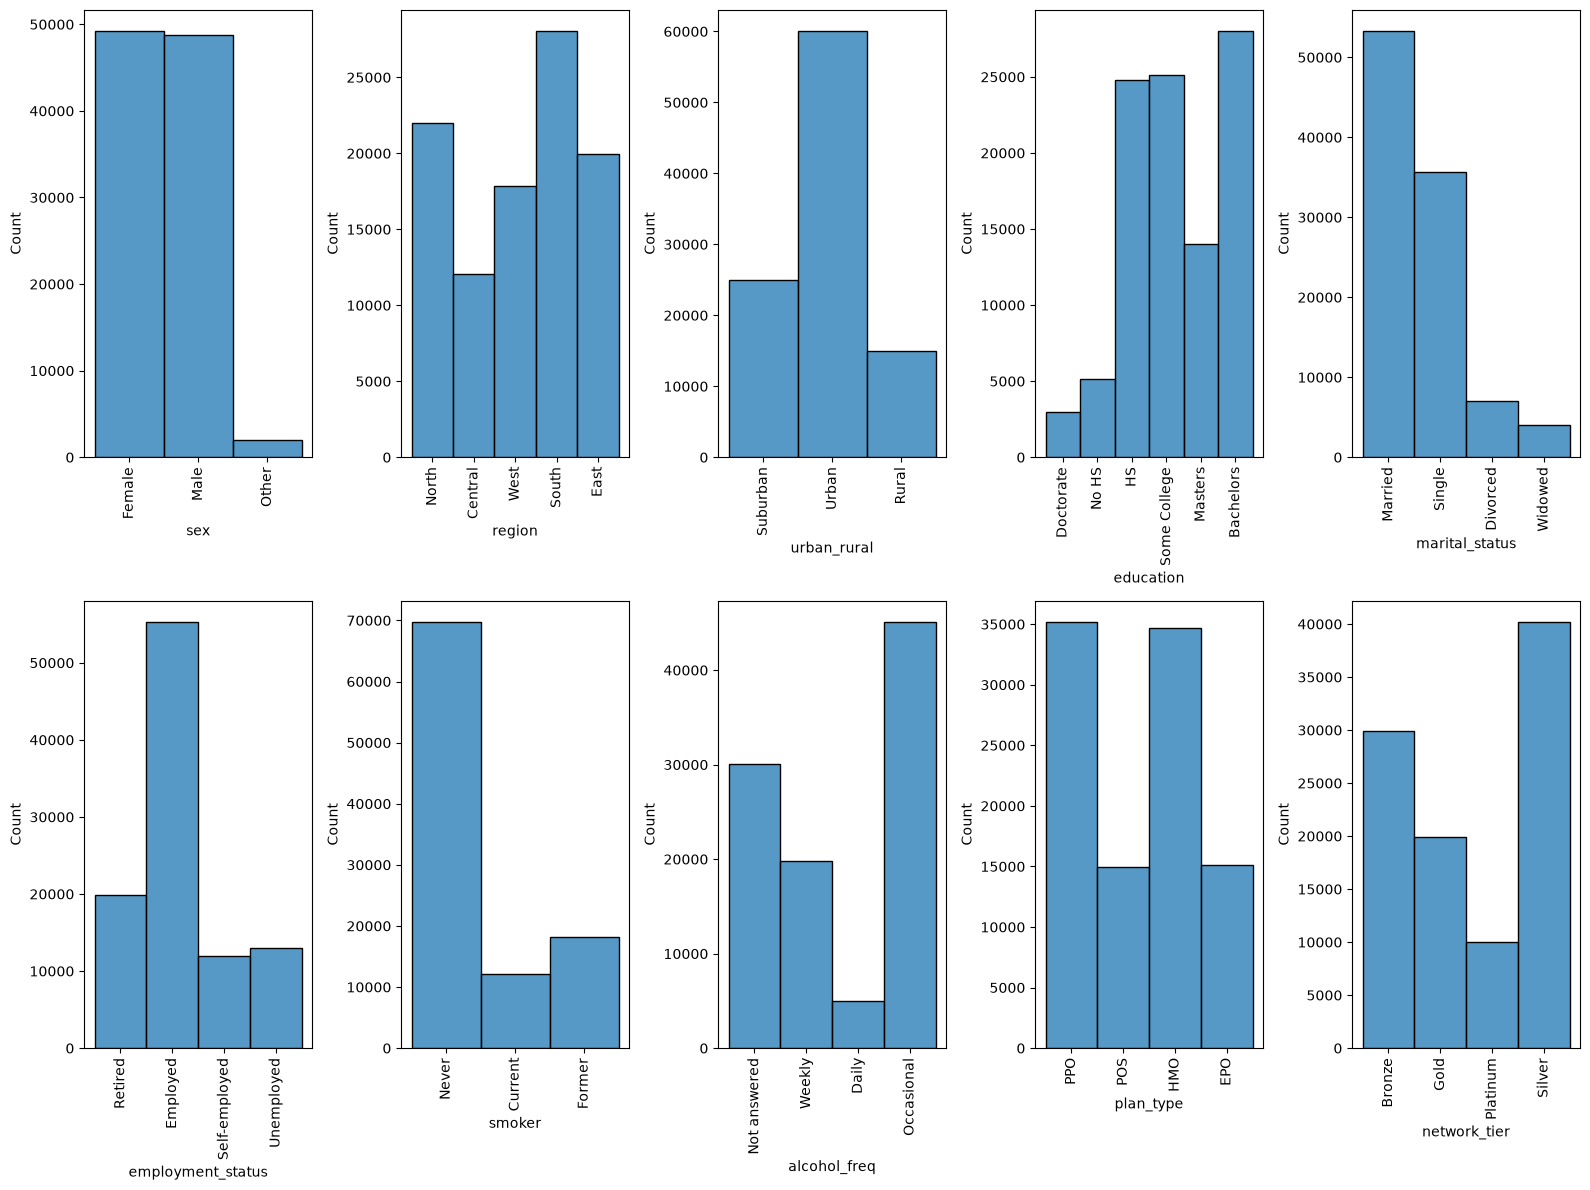

In [14]:
plt.figure(figsize=(16,12))
for i,col in enumerate(df.select_dtypes('str').columns):
    plt.subplot(2, 5, i+1)
    sns.histplot(df[col])
    plt.xticks(rotation=90)
plt.tight_layout()

<Axes: xlabel='annual_medical_cost', ylabel='Count'>

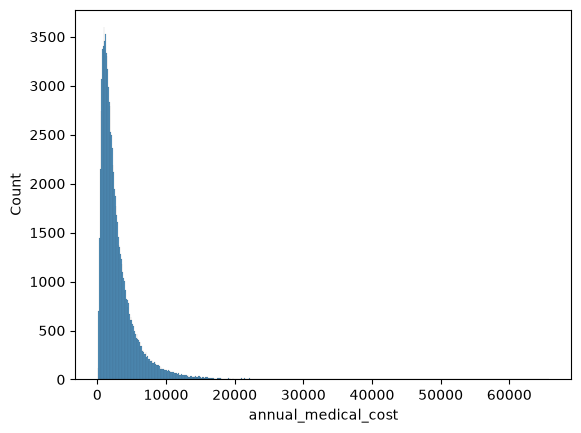

In [15]:
sns.histplot(df['annual_medical_cost'])

<Axes: ylabel='annual_medical_cost'>

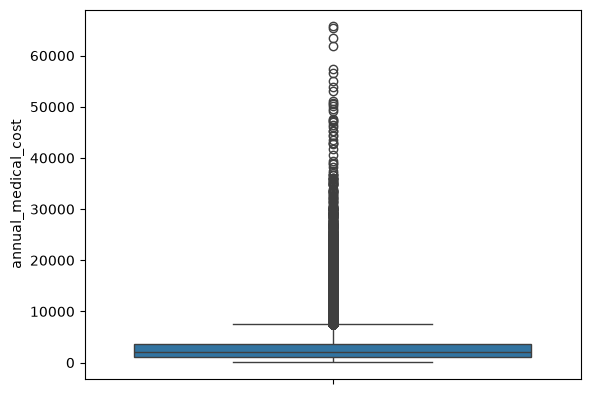

In [16]:
sns.boxplot(df['annual_medical_cost'])

## Корреляционный анализ

In [17]:
import phik
from phik import significance_matrix

In [18]:
correlation_for_depended = pd.DataFrame(df.phik_matrix(interval_cols=df.select_dtypes(['float64', 'int64']))['annual_medical_cost'].drop('annual_medical_cost').sort_values(), columns=['annual_medical_cost'])

<Axes: >

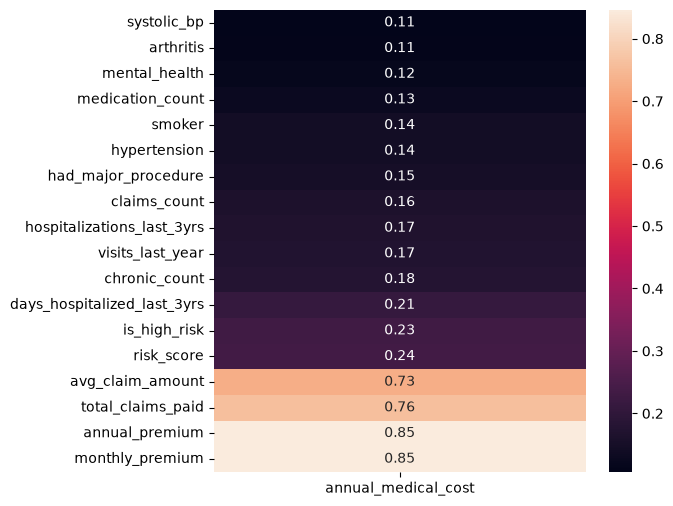

In [19]:
plt.figure(figsize=(6,6))
sns.heatmap(correlation_for_depended[correlation_for_depended['annual_medical_cost'] > 0.1], annot=True)

In [20]:
significance = df[list(df.select_dtypes('str').columns) + columns_already_unpacked + ['annual_medical_cost']].significance_matrix()

interval columns not set, guessing: ['hypertension', 'diabetes', 'asthma', 'copd', 'cardiovascular_disease', 'cancer_history', 'kidney_disease', 'liver_disease', 'arthritis', 'mental_health', 'is_high_risk', 'had_major_procedure', 'annual_medical_cost']


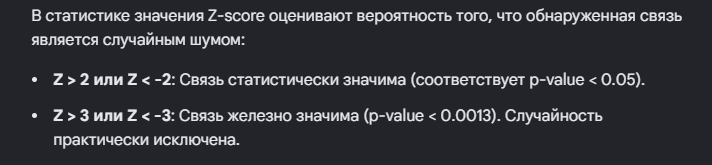

In [21]:
significance_of_nominiative_variables_for_depended = abs(significance['annual_medical_cost']).drop('annual_medical_cost')[abs(significance['annual_medical_cost']) > 2]

In [22]:
significance_of_nominiative_variables_for_depended

smoker                    33.372439
hypertension              31.894243
diabetes                  20.993900
asthma                    15.708138
copd                      13.119327
cardiovascular_disease    15.872886
cancer_history            10.373428
kidney_disease             9.241394
liver_disease              9.220761
arthritis                 23.949302
mental_health             25.466834
is_high_risk              54.669298
had_major_procedure       32.687435
Name: annual_medical_cost, dtype: float64

In [23]:
true_cont_variables = df.select_dtypes(['float64', 'int64']).drop(columns_already_unpacked,axis=1).columns
significance_continuous= df[true_cont_variables].significance_matrix(interval_cols=true_cont_variables)

In [24]:
significance_of_conitnious_variables_for_depended = abs(significance_continuous['annual_medical_cost']).drop('annual_medical_cost')[abs(significance_continuous['annual_medical_cost']) > 2]

In [25]:
significance_of_conitnious_variables_for_depended

age                             23.176080
bmi                              2.747123
visits_last_year                37.587585
hospitalizations_last_3yrs      43.165713
days_hospitalized_last_3yrs     44.915661
medication_count                20.409706
systolic_bp                     26.786729
diastolic_bp                    21.606206
hba1c                           16.063696
risk_score                      64.036526
annual_premium                 172.596707
monthly_premium                172.608686
claims_count                    32.948679
avg_claim_amount               109.533976
total_claims_paid              123.052412
chronic_count                   62.655061
proc_imaging_count              12.302167
proc_surgery_count              17.191932
proc_physio_count                9.553621
proc_consult_count              11.121020
proc_lab_count                  11.321324
Name: annual_medical_cost, dtype: float64

In [26]:
len(df.columns) - len(df[list(significance_of_conitnious_variables_for_depended.index) + list(significance_of_nominiative_variables_for_depended.index)].columns)

19

In [27]:
df_changed = df[list(significance_of_conitnious_variables_for_depended.index) + list(significance_of_nominiative_variables_for_depended.index) + ['annual_medical_cost']]

In [28]:
df_changed.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 35 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   age                          100000 non-null  int64  
 1   bmi                          100000 non-null  float64
 2   visits_last_year             100000 non-null  int64  
 3   hospitalizations_last_3yrs   100000 non-null  int64  
 4   days_hospitalized_last_3yrs  100000 non-null  int64  
 5   medication_count             100000 non-null  int64  
 6   systolic_bp                  100000 non-null  float64
 7   diastolic_bp                 100000 non-null  float64
 8   hba1c                        100000 non-null  float64
 9   risk_score                   100000 non-null  float64
 10  annual_premium               100000 non-null  float64
 11  monthly_premium              100000 non-null  float64
 12  claims_count                 100000 non-null  int64  
 13  avg_claim_a

## Построение моделей линейной регрессии

In [29]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, HuberRegressor
from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, root_mean_squared_error, r2_score

In [30]:
X = df_changed.drop('annual_medical_cost', axis=1)
y = df_changed['annual_medical_cost']

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [32]:
# Определяем группы колонок
cols_to_scale = [c for c in X.columns if c not in columns_already_unpacked + ['smoker']]
cols_to_dummify = ['smoker']
cols_to_keep = columns_already_unpacked  # уже распакованные дамми

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), cols_to_scale),           # масштабируем числовые
        ('cat', OneHotEncoder(drop='first'), cols_to_dummify),  # smoker → дамми
        ('passthrough', 'passthrough', cols_to_keep)        # оставляем как есть
    ],
    remainder='drop'
)

# Применяем
X_train_final = preprocessor.fit_transform(X_train)
X_test_final = preprocessor.transform(X_test)


feature_names = (
    cols_to_scale +
    list(preprocessor.named_transformers_['cat'].get_feature_names_out(['smoker'])) +
    cols_to_keep
)

In [33]:
dict_for_results = {}

In [34]:
linear_regression = LinearRegression()
linear_regression.fit(X_train_final, y_train)
linear_preds = linear_regression.predict(X_test_final)
dict_for_results['Linear'] = [mean_absolute_error(y_test, linear_preds), root_mean_squared_error(y_test, linear_preds), mean_absolute_percentage_error(y_test, linear_preds), r2_score(y_test,linear_preds)]

In [35]:
params_lasso = {'alpha': np.arange(0.1, 1, 0.1)}
grid_lasso = GridSearchCV(estimator=Lasso(max_iter=10000), param_grid=params_lasso, cv=5, scoring='r2')
grid_lasso.fit(X_train_final, y_train)
print(grid_lasso.best_estimator_)
grid_lasso_pred = grid_lasso.predict(X_test_final)
dict_for_results['Lasso'] = [mean_absolute_error(y_test, grid_lasso_pred), root_mean_squared_error(y_test, grid_lasso_pred), mean_absolute_percentage_error(y_test, grid_lasso_pred), r2_score(y_test,grid_lasso_pred)]

Lasso(alpha=np.float64(0.8), max_iter=10000)


In [36]:
params_ridge = {'alpha': np.arange(0.1, 1, 0.1)}
grid_ridge = GridSearchCV(estimator=Ridge(max_iter=10000), param_grid=params_ridge, cv=5, scoring='r2')
grid_ridge.fit(X_train_final, y_train)
print(grid_ridge.best_estimator_)
grid_ridge_preds = grid_ridge.predict(X_test_final)
dict_for_results['Ridge'] = [mean_absolute_error(y_test, grid_ridge_preds), root_mean_squared_error(y_test, grid_ridge_preds), mean_absolute_percentage_error(y_test, grid_ridge_preds),r2_score(y_test, grid_ridge_preds)]

Ridge(alpha=np.float64(0.9), max_iter=10000)


In [39]:
params_huber = {'epsilon': np.arange(1, 2, 0.1)}
grid_huber = GridSearchCV(HuberRegressor(max_iter=1000, alpha=0.8), param_grid=params_huber, scoring='r2')
grid_huber.fit(X_train_final, y_train)
print(grid_huber.best_estimator_)
grid_huber_preds = grid_huber.predict(X_test_final)
dict_for_results['Huber'] = [mean_absolute_error(y_test, grid_huber_preds), root_mean_squared_error(y_test, grid_huber_preds), mean_absolute_percentage_error(y_test, grid_huber_preds),r2_score(y_test, grid_huber_preds)]

HuberRegressor(alpha=0.8, epsilon=np.float64(1.9000000000000008), max_iter=1000)


## Построение моделей с деревьями

In [41]:
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor, GradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV

In [42]:
params_rnd_forest = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 15, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

rnd_forest = RandomizedSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_distributions=params_rnd_forest,
    n_iter=3,
    scoring='r2',
    cv=5,
    n_jobs=-1,  # параллельно по всем ядрам
    random_state=42,
    verbose=1  # показывать прогресс
)
rnd_forest.fit(X_train_final, y_train)
rnd_forest_preds = rnd_forest.predict(X_test_final)
print(rnd_forest.best_estimator_)
dict_for_results['Random_Forest'] = [mean_absolute_error(y_test, rnd_forest_preds), root_mean_squared_error(y_test, rnd_forest_preds), mean_absolute_percentage_error(y_test, rnd_forest_preds),r2_score(y_test, rnd_forest_preds)]

Fitting 5 folds for each of 3 candidates, totalling 15 fits
RandomForestRegressor(max_depth=10, min_samples_split=5, n_estimators=200,
                      n_jobs=-1, random_state=42)


In [43]:
params_adaBoost = {'learning_rate': np.arange(0.1, 1.5, 0.2)}
grid_adaBoost = GridSearchCV(AdaBoostRegressor(), param_grid=params_adaBoost, n_jobs=-1, verbose=1)
grid_adaBoost.fit(X_train_final, y_train)
grid_adaBoost_preds = rnd_forest.predict(X_test_final)
print(grid_adaBoost.best_estimator_)
dict_for_results['AdaBoost'] = [mean_absolute_error(y_test, grid_adaBoost_preds), root_mean_squared_error(y_test, grid_adaBoost_preds), mean_absolute_percentage_error(y_test, grid_adaBoost_preds),r2_score(y_test, grid_adaBoost_preds)]

Fitting 5 folds for each of 7 candidates, totalling 35 fits
AdaBoostRegressor(learning_rate=np.float64(0.1))


In [44]:
params_GradientBoost = {'loss': ['squared_error', 'huber', 'quantile'], }
grid_GradientBoost = GridSearchCV(GradientBoostingRegressor(n_estimators=200), param_grid=params_GradientBoost, n_jobs=-1, verbose=1)
grid_GradientBoost.fit(X_train_final, y_train)
grid_GradientBoost_preds = rnd_forest.predict(X_test_final)
print(grid_GradientBoost.best_estimator_)
dict_for_results['GradientBoosting'] = [mean_absolute_error(y_test, grid_GradientBoost_preds), root_mean_squared_error(y_test, grid_GradientBoost_preds), mean_absolute_percentage_error(y_test, grid_GradientBoost_preds),r2_score(y_test, grid_GradientBoost_preds)]

Fitting 5 folds for each of 3 candidates, totalling 15 fits
GradientBoostingRegressor(loss='huber', n_estimators=200)


## Факторный анализ и описание результатов

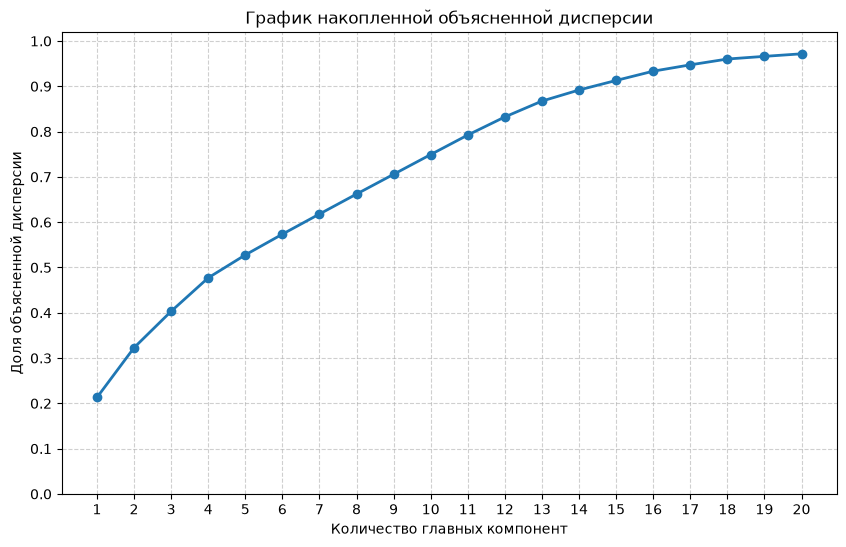

In [45]:
pca = PCA(n_components=20)
pca.fit(X_train_final)
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
components = np.arange(1, 21)

plt.figure(figsize=(10, 6))
plt.plot(components, cumulative_variance, marker='o', linestyle='-', linewidth=2)
plt.title('График накопленной объясненной дисперсии')
plt.xlabel('Количество главных компонент')
plt.ylabel('Доля объясненной дисперсии')

plt.xticks(components)
plt.yticks(np.arange(0, 1.1, 0.1))
plt.grid(True, linestyle='--', alpha=0.6)
plt.ylim(0, 1.02);

In [46]:
pca_15 = PCA(n_components=15)
X_train_pca = pca_15.fit_transform(X_train_final)
X_test_pca = pca_15.transform(X_test_final)
Linear_pca = LinearRegression()
Linear_pca.fit(X_train_pca, y_train)
pca_preds = Linear_pca.predict(X_test_pca)
dict_for_results['PCA'] = [mean_absolute_error(y_test, pca_preds), root_mean_squared_error(y_test, pca_preds), mean_absolute_percentage_error(y_test, pca_preds), r2_score(y_test, pca_preds)]

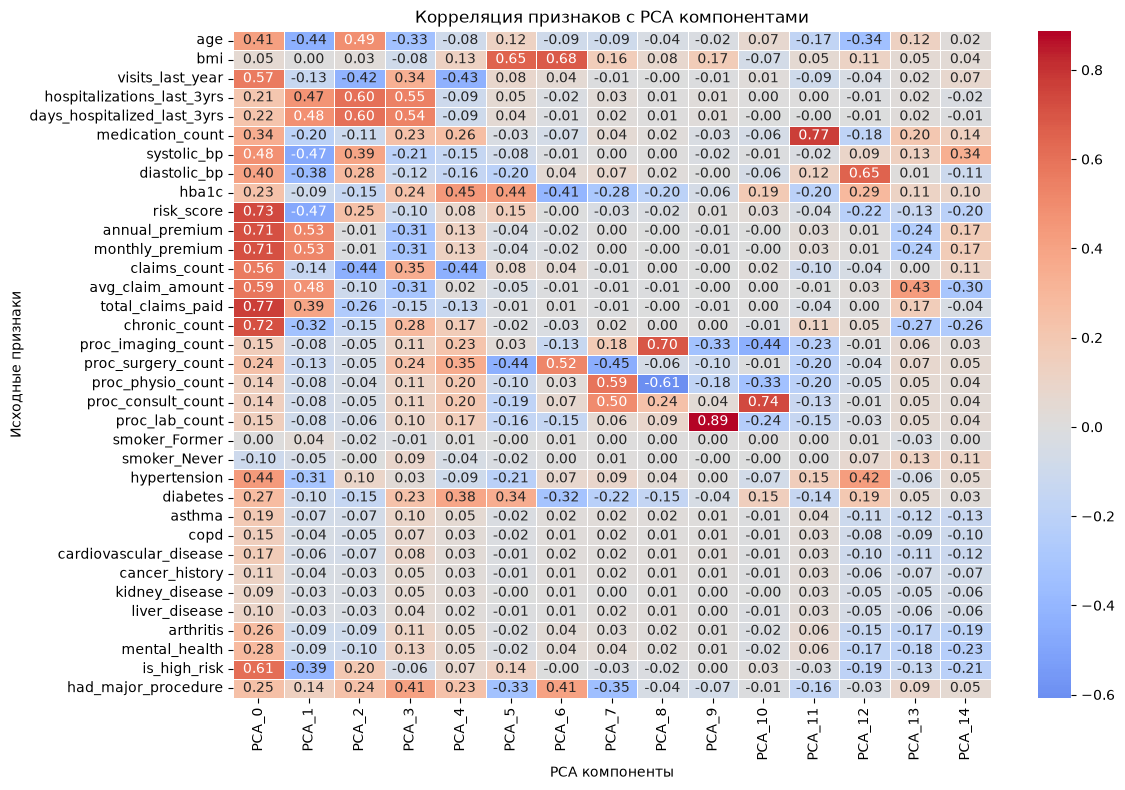

In [47]:
# 1. Сначала создаём отдельные DataFrame
df_original = pd.DataFrame(X_train_final, columns=feature_names)
df_pca = pd.DataFrame(X_train_pca, columns=[f'PCA_{i}' for i in range(X_train_pca.shape[1])])

# 2. Объединяем по колонкам (axis=1)
df_combined = pd.concat([df_original, df_pca], axis=1)
original_cols = feature_names
pca_cols = [f'PCA_{i}' for i in range(X_train_pca.shape[1])]

# Считаем корреляцию
corr_matrix = df_combined[original_cols + pca_cols].corr()

# Берём только блок "признаки × PCA"
corr_block = corr_matrix.loc[original_cols, pca_cols]
plt.figure(figsize=(12, 8))
sns.heatmap(corr_block, annot=True, cmap='coolwarm', center=0, 
            fmt='.2f', linewidths=0.5)
plt.title('Корреляция признаков с PCA компонентами')
plt.xlabel('PCA компоненты')
plt.ylabel('Исходные признаки')
plt.tight_layout()
plt.show()

In [48]:
for pca_col in pca_cols:
    print(f"\n=== {pca_col} ===")
    correlations = corr_block[pca_col].abs().sort_values(ascending=False)
    top_5 = correlations.head(5)
    for feat, corr in top_5.items():
        sign = '+' if corr_block.loc[feat, pca_col] > 0 else '-'
        print(f"  {sign} {feat}: {corr:.3f}")


=== PCA_0 ===
  + total_claims_paid: 0.772
  + risk_score: 0.730
  + chronic_count: 0.717
  + monthly_premium: 0.713
  + annual_premium: 0.713

=== PCA_1 ===
  + monthly_premium: 0.525
  + annual_premium: 0.525
  + days_hospitalized_last_3yrs: 0.484
  + avg_claim_amount: 0.476
  - risk_score: 0.474

=== PCA_2 ===
  + days_hospitalized_last_3yrs: 0.603
  + hospitalizations_last_3yrs: 0.603
  + age: 0.485
  - claims_count: 0.438
  - visits_last_year: 0.424

=== PCA_3 ===
  + hospitalizations_last_3yrs: 0.548
  + days_hospitalized_last_3yrs: 0.535
  + had_major_procedure: 0.408
  + claims_count: 0.349
  + visits_last_year: 0.337

=== PCA_4 ===
  + hba1c: 0.446
  - claims_count: 0.441
  - visits_last_year: 0.431
  + diabetes: 0.383
  + proc_surgery_count: 0.355

=== PCA_5 ===
  + bmi: 0.651
  - proc_surgery_count: 0.443
  + hba1c: 0.436
  + diabetes: 0.345
  - had_major_procedure: 0.330

=== PCA_6 ===
  + bmi: 0.680
  + proc_surgery_count: 0.521
  + had_major_procedure: 0.407
  - hba1c: 0

In [49]:
pca_names = {
    'PCA_0':  'Общий_финансовый_риск',
    'PCA_1':  'Финансовая_нагрузка_и_госпитализация',
    'PCA_2':  'История_госпитализаций_и_возраст',
    'PCA_3':  'Интенсивность_мед_обслуживания',
    'PCA_4':  'Диабет_и_хирургия',
    'PCA_5':  'Метаболическое_здоровье',
    'PCA_6':  'Ожирение_и_хирургические_риски',
    'PCA_7':  'Процедурная_активность',
    'PCA_8':  'Диагностическая_активность',
    'PCA_9':  'Лабораторно_диагностическая',
    'PCA_10': 'Консультационно_диагностическая',
    'PCA_11': 'Медикаментозная_нагрузка',
    'PCA_12': 'Кардиоваскулярный_риск',
    'PCA_13': 'Хроническая_финансовая_нагрузка',
    'PCA_14': 'Систолическое_давление_и_ментальное_здоровье'
}

# Переименовываем колонки в DataFrame
df_pca = pd.DataFrame(X_train_pca, columns=[f'PCA_{i}' for i in range(X_train_pca.shape[1])])
df_pca = df_pca.rename(columns=pca_names)
df_pca

,Общий_финансовый_риск,Финансовая_нагрузка_и_госпитализация,История_госпитализаций_и_возраст,Интенсивность_мед_обслуживания,Диабет_и_хирургия,Метаболическое_здоровье,Ожирение_и_хирургические_риски,Процедурная_активность,Диагностическая_активность,Лабораторно_диагностическая,Консультационно_диагностическая,Медикаментозная_нагрузка,Кардиоваскулярный_риск,Хроническая_финансовая_нагрузка,Систолическое_давление_и_ментальное_здоровье
0,1.129006,0.335718,1.279397,-2.701581,-0.512406,-0.273608,0.378202,0.664264,0.202979,0.395727,-1.348017,-0.975196,-0.424167,0.362264,0.123219
1,-0.569060,0.333686,-0.034248,-0.523603,0.934114,0.121983,-1.399881,-1.077186,-0.336777,1.990741,-0.130631,-0.732262,0.459149,-1.171212,0.548355
2,-0.422720,-1.395807,0.644665,-0.400231,0.606209,2.204216,0.968848,0.026700,1.822316,-0.749876,-1.073935,0.278475,-2.118067,-0.118340,-0.399709
3,-2.380970,0.736896,-0.084085,-0.645619,-0.149073,0.951859,1.506173,0.559321,-0.807920,-0.098739,-0.509691,-0.123778,0.456739,-0.426033,0.278063
4,-2.442331,0.290256,-0.076436,-0.203566,0.627657,0.771652,0.337677,-0.166628,0.921008,0.728082,-0.860743,0.159388,0.547150,0.256990,0.376973
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79995,0.548977,-1.881095,0.604317,-0.454363,-0.979534,0.399654,0.708751,-0.101572,0.304560,3.646552,-0.977383,-0.598853,1.421318,-0.064502,-0.080591
79996,0.010748,-1.206976,-0.124108,1.118517,1.091962,-4.366054,1.417254,-1.153140,-0.823388,0.026712,0.189934,-1.156361,1.005149,-0.452189,-0.054741
79997,-0.612572,-1.109633,0.796120,-0.082376,1.560757,-0.368741,0.795494,-1.650019,0.618500,0.301752,-0.631570,-0.715333,-1.320243,-0.127699,0.030651
79998,0.898560,-1.206774,0.060504,-0.229520,-0.284792,0.175809,0.102301,0.564781,0.339329,-0.164525,2.202758,0.639088,0.325295,0.079067,-0.559312


## Интерпретация ошибок моделей

In [50]:
pd.DataFrame(data=dict_for_results.values(), columns=['MAE', 'RMSE', 'MAPE', 'R2'], index=dict_for_results.keys())

,MAE,RMSE,MAPE,R2
Linear,453.306156,772.365649,0.178941,0.939376
Lasso,452.929165,772.270067,0.178891,0.939391
Ridge,453.276798,772.341978,0.178936,0.939380
Huber,447.863276,773.169991,0.169489,0.939250
Random_Forest,395.139295,704.925470,0.139178,0.949501
AdaBoost,395.139295,704.925470,0.139178,0.949501
GradientBoosting,395.139295,704.925470,0.139178,0.949501
PCA,480.742861,790.267182,0.203073,0.936533


In [51]:
# Разделим данные на группы по величине y
bins = [0, 2000, 5000, 10000, 20000, 100000]
labels = ['0-2k', '2k-5k', '5k-10k', '10k-20k', '20k+']

y_test_binned = pd.cut(y_test, bins=bins, labels=labels)

# MAE по каждой группе
for label in labels:
    mask = y_test_binned == label
    if mask.sum() > 0:
        mae_group = mean_absolute_error(y_test[mask], rnd_forest_preds[mask])
        median_group = y_test[mask].median()
        print(f"Группа {label}: MAE={mae_group:.0f}, Медиана={median_group:.0f}, "
              f"MAE/Медиана={mae_group/median_group*100:.1f}%, Кол-во={mask.sum()}")

Группа 0-2k: MAE=166, Медиана=1156, MAE/Медиана=14.3%, Кол-во=9560
Группа 2k-5k: MAE=395, Медиана=3003, MAE/Медиана=13.2%, Кол-во=7373
Группа 5k-10k: MAE=864, Медиана=6503, MAE/Медиана=13.3%, Кол-во=2372
Группа 10k-20k: MAE=1708, Медиана=12240, MAE/Медиана=14.0%, Кол-во=618
Группа 20k+: MAE=3912, Медиана=24378, MAE/Медиана=16.0%, Кол-во=77


Ансамблевые модели (Random Forest, AdaBoost, GradientBoosting) продемонстрировали 
наилучшее качество прогнозирования годовых медицинских расходов:

- **R² = 0.9495** — модель объясняет ~95% дисперсии целевой переменной
- **MAPE = 13.92%** — средняя процентная ошибка составляет ~14%
- **MAE = 395$** — абсолютная ошибка в среднем составляет 395 долларов

По сравнению с линейными моделями (R² ≈ 0.939, MAPE ≈ 17.9%), ансамблевые методы 
показали прирост качества: R² увеличился на ~1%, MAPE снизился на ~4 процентных пункта.

Анализ ошибок по группам расходов показал стабильность модели: относительная ошибка 
(MAE/медиана) составляет 13-16% во всех диапазонах, включая группу с высокими 
расходами (>20 000$), что свидетельствует о робастности модели.

Улучшение качества объясняется способностью деревьев улавливать нелинейные зависимости 
и взаимодействия признаков, а также устойчивостью к выбросам в данных.

## Коэффициенты лучшей линейной модели Lasso

=== Коэффициенты Lasso (отсортированы по важности) ===
                    feature  coefficient
             annual_premium  2689.005937
          total_claims_paid   390.258813
               claims_count  -136.970762
                 risk_score    62.832004
           avg_claim_amount    51.828931
               smoker_Never   -51.003479
days_hospitalized_last_3yrs    48.795456
        had_major_procedure    29.561069
              chronic_count    28.212839
                        age   -15.573865
         proc_surgery_count   -11.105372
              smoker_Former   -10.603580
           visits_last_year   -10.030293
               hypertension     7.185979
                        bmi     6.626799
               is_high_risk    -3.202565
             proc_lab_count     3.020668
         proc_imaging_count    -2.809666
                      hba1c    -2.655785
 hospitalizations_last_3yrs     2.287147
         proc_consult_count     2.071878
           medication_count     2.005522
  

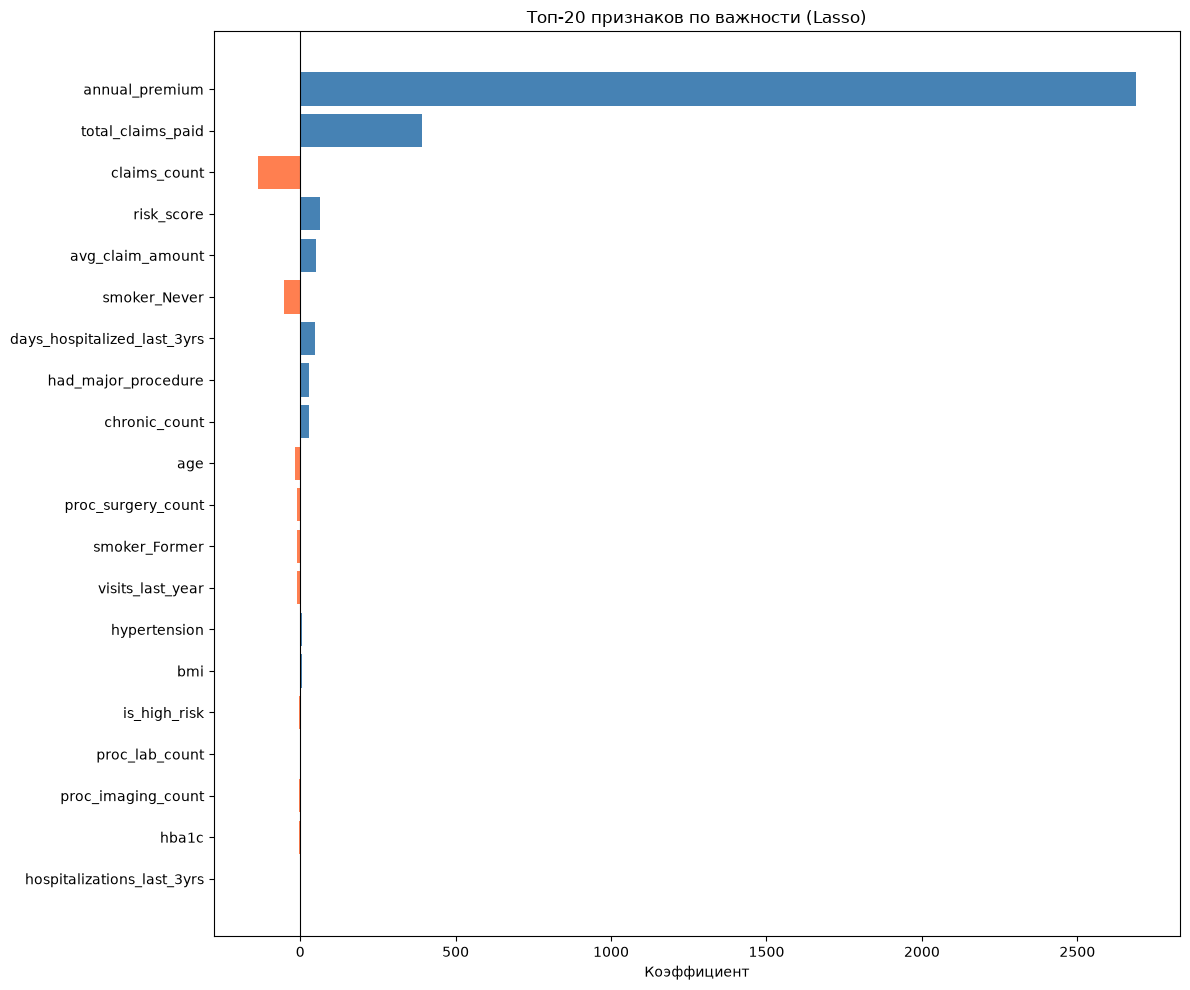

In [103]:
# 1. Создаём DataFrame с коэффициентами
df_coef = pd.DataFrame({
    'feature': feature_names,
    'coefficient': grid_lasso.best_estimator_.coef_.flatten()
})

# 2. Добавляем абсолютное значение и сортируем
df_coef['abs_coef'] = df_coef['coefficient'].abs()
df_coef = df_coef.sort_values('abs_coef', ascending=False).reset_index(drop=True)

# 3. Выводим
print("=== Коэффициенты Lasso (отсортированы по важности) ===")
print(df_coef[['feature', 'coefficient']].to_string(index=False))

# 4. Визуализация топ-20
plt.figure(figsize=(12, 10))
top_20 = df_coef.head(20)
colors = ['steelblue' if x > 0 else 'coral' for x in top_20['coefficient']]
plt.barh(range(len(top_20)), top_20['coefficient'][::-1], color=colors[::-1])
plt.yticks(range(len(top_20)), top_20['feature'][::-1])
plt.xlabel('Коэффициент')
plt.title('Топ-20 признаков по важности (Lasso)')
plt.axvline(x=0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

Модель Lasso регрессии демонстрирует высокое качество прогнозирования (R² = 0.94). Относительная ошибка (MAE/медиана) составляет стабильные 15-18% во всех диапазонах значений целевой переменной, включая группу с высокими расходами (>20 000$), что свидетельствует о робастности модели. Абсолютная ошибка пропорционально растёт с величиной расходов, что является ожидаемым поведением для данной задачи.

## Итоги

### Итоги проекта

В кейсе был проведен комплексный анализ и построение прогнозной модели для оценки годовых медицинских расходов (`annual_medical_cost`) на основе обширного датасета, включающего 100 000 записей с демографическими, клиническими и страховыми показателями. Важным этапом стала предобработка данных и конструирование признаков, включая метод главных компонент (PCA). Применение PCA позволило агрегировать множество разрозненных медицинских показателей в осмысленные латентные факторы, такие как «Общий финансовый риск», «Метаболическое здоровье» и «Кардиоваскулярный риск», что улучшило интерпретируемость данных.

В ходе эксперимента были обучены и протестированы различные классы моделей: от базовых линейных регрессий (Linear, Lasso, Ridge, Huber) до сложных ансамблевых алгоритмов (Random Forest, AdaBoost, Gradient Boosting). Линейные модели показали высокий базовый уровень качества (R² ≈ 0.939, MAPE ≈ 17.9%), однако ансамбли на основе деревьев решений продемонстрировали наилучший результат. Лучшие модели достигли значения R² ≈ 0.95 и средней процентной ошибки (MAPE) около 13.9%, что подтверждает наличие в данных сложных нелинейных взаимосвязей, которые успешно улавливаются ансамблевыми методами.

Анализ важности признаков показал, что ключевыми драйверами медицинских расходов являются страховые метрики и история обращений: `annual_premium`, `total_claims_paid`, `claims_count` и интегральный показатель `risk_score`. Дополнительный анализ ошибок по сегментам расходов доказал робастность итоговой модели: относительная ошибка (MAE/Медиана) оставалась стабильной в диапазоне 13–16% для всех групп пациентов, включая сегмент с экстремально высокими затратами (>20 000$). 